# What's new in PyHealth 2.1 (3/3): XGBoost with exact explanations, medical-code translation and new processors

Three additions that make strong baselines and messy codes easier:

- **`XGBoostModel`**: gradient-boosted trees that train with one `fit` call and plug into the usual `Trainer` evaluation, with exact TreeSHAP explanations.
- **ICD-9 ↔ ICD-10 translation and CCSR groupings** in `CrossMap`, with unmapped codes reported, not silently dropped.
- **`nested_multihot`**, a per-visit encoding of which codes are present, and `TensorProcessor.size()`.

**Time:** about 10 minutes on a free Colab CPU runtime.

**How to run:** Runtime > Run all, or Shift+Enter cell by cell. The text above each code cell says what it does; the text below says how to read its output.

## Visual guide

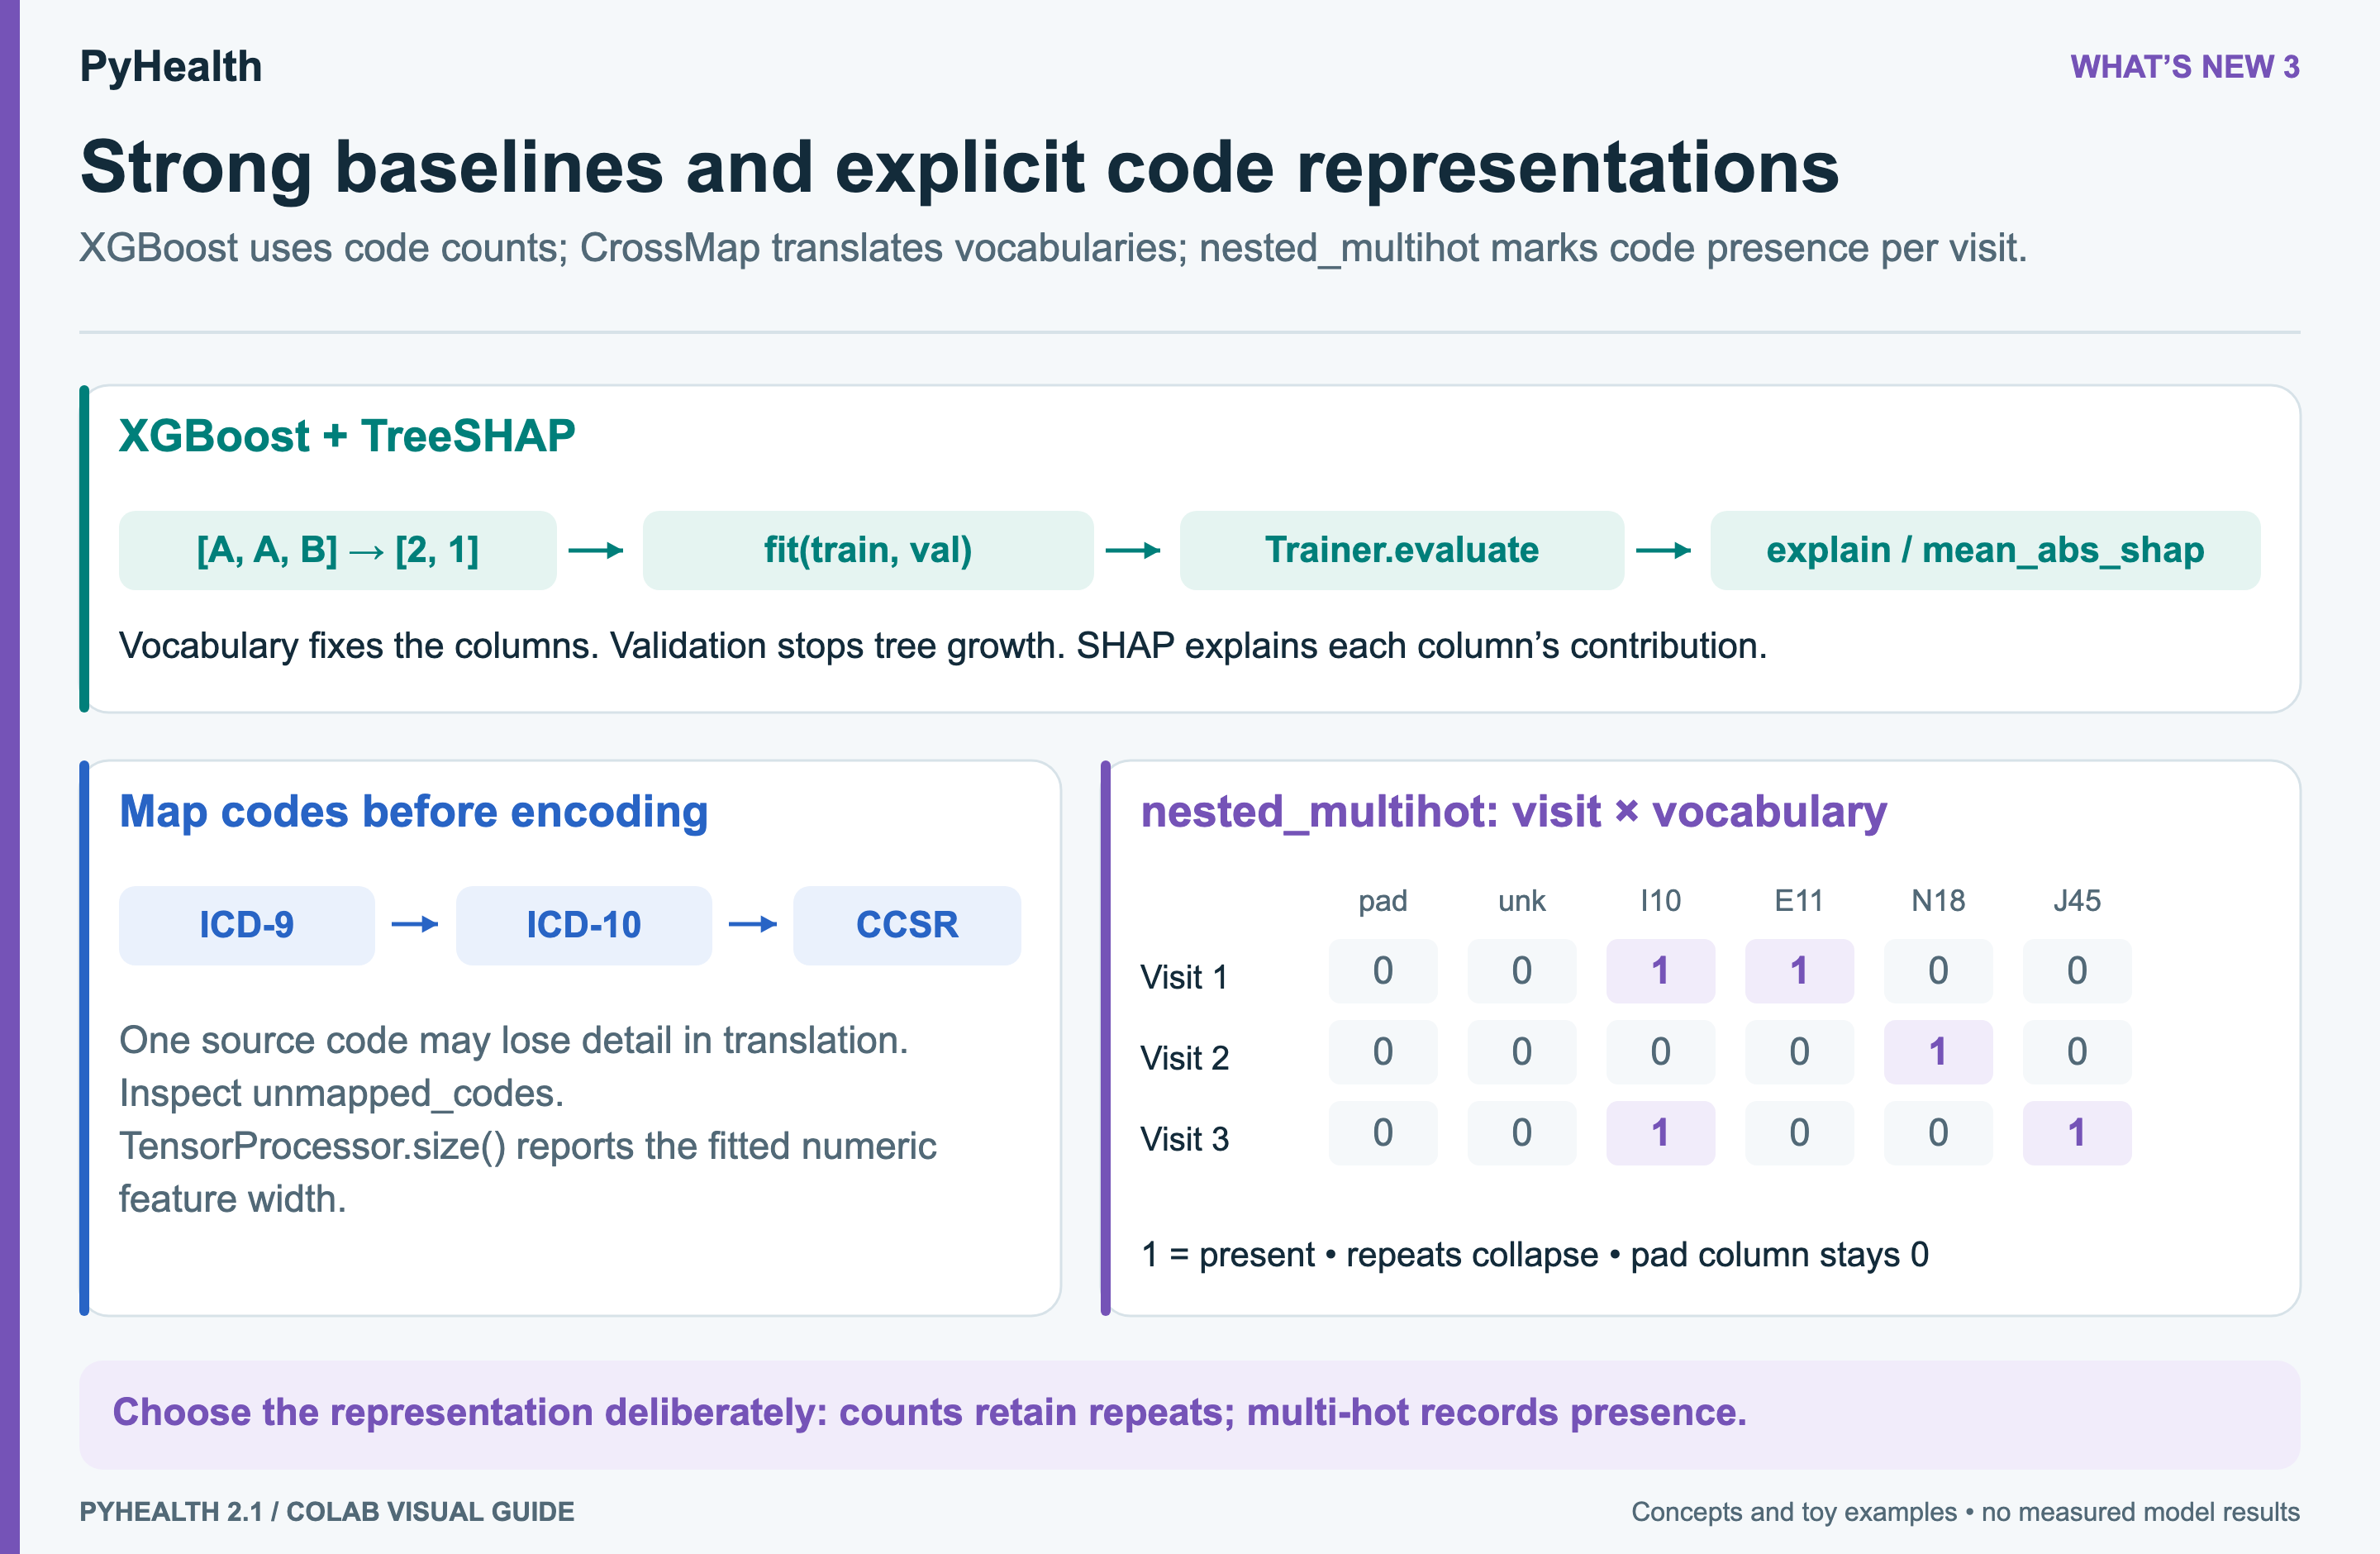

XGBoost code counts retain duplicates, while nested_multihot stores presence per visit. CrossMap translations and TensorProcessor widths complete the representation workflow.


## Setup

This installs **PyHealth 2.1.0** from PyPI. On Colab choose **Runtime > Run all**. If the install has to upgrade a package Colab already loaded, the runtime restarts once ("Your session crashed"); choose **Runtime > Run all** again. Output is kept short: PyHealth's step-by-step build logs are hidden.

In [1]:
# Installs PyHealth 2.1.0 from PyPI (about 1-2 minutes the first time).
# If the install upgrades a package Python has already loaded (Colab
# preloads a few, such as numpy), the runtime restarts once: Colab then
# shows "Your session crashed". That is expected. Choose Runtime > Run all
# again and everything runs through; this cell will then skip the install.
import importlib.metadata as md
import os
import subprocess
import sys

PYHEALTH_VERSION = "2.1.0"
EXTRAS = "xgboost"


def installed(dist):
    try:
        return md.version(dist)
    except md.PackageNotFoundError:
        return None


if installed("pyhealth") != PYHEALTH_VERSION:
    # Remember which installed packages are already imported, and at what version.
    owners = md.packages_distributions()
    loaded = {}
    for module in list(sys.modules):
        for dist in owners.get(module, []):
            loaded[dist] = installed(dist)

    print(f"Installing PyHealth {PYHEALTH_VERSION}...")
    result = subprocess.run(
        # ipywidgets draws the progress bars while a dataset is built; Colab
        # already has it, other Jupyter setups may not.
        [sys.executable, "-m", "pip", "install", "-q",
         f"pyhealth[{EXTRAS}]=={PYHEALTH_VERSION}", "ipywidgets"],
        capture_output=True, text=True,
    )
    if result.returncode != 0:
        print(result.stdout[-5000:], result.stderr[-5000:])
        raise RuntimeError("Installing PyHealth failed; see the log above.")

    changed = sorted(d for d, v in loaded.items() if installed(d) != v)
    if changed:
        print("Upgraded packages that were already loaded:", ", ".join(changed))
        print("Restarting the runtime. When Colab says the session crashed, "
              "choose Runtime > Run all again.")
        os.kill(os.getpid(), 9)  # Colab restarts the runtime automatically

import logging
import warnings

import pyhealth
import torch

# Keep the output readable: hide the step-by-step logs of dataset and task
# building (progress bars still show), keep the per-epoch training scores,
# and skip the printout of every model's layers. To see everything, run
# logging.getLogger("pyhealth").setLevel(logging.INFO)
logging.getLogger("pyhealth").setLevel(logging.WARNING)
logging.getLogger("pyhealth.trainer").setLevel(logging.INFO)
logging.getLogger("pyhealth.trainer").addFilter(
    lambda record: not isinstance(record.msg, torch.nn.Module))
# PyHealth 2.1.0 pins litdata, which then suggests upgrading on every run.
warnings.filterwarnings("ignore", message="A newer version of litdata")
print(f"PyHealth {installed('pyhealth')} is ready | "
      f"device: {'GPU (' + torch.cuda.get_device_name(0) + ')' if torch.cuda.is_available() else 'CPU'}")

Installing PyHealth 2.1.0...
PyHealth 2.1.0 is ready | device: CPU


## Load the data and define the task

The public synthetic copy of MIMIC-III (no credentials). The question, from Tutorial 04: **does an admission include a heart-failure diagnosis, judged from its medications and procedures?** It is a custom task in about 25 lines, and it has real signal, unlike synthetic mortality, which is close to random. Admissions are split by patient, with preprocessing fitted on training patients only (part 1 of this series). The first run downloads and caches the tables (a few minutes).

In [2]:
from collections import defaultdict

from pyhealth.datasets import MIMIC3Dataset, PatientSplit, get_dataloader
from pyhealth.tasks import BaseTask


class HeartFailureFromMedications(BaseTask):
    """Does an admission include a heart-failure diagnosis (ICD-9 428.x)?"""

    task_name = "HeartFailureFromMedications"
    input_schema = {"drugs": "sequence", "procedures": "sequence"}
    output_schema = {"heart_failure": "binary"}

    def __call__(self, patient):
        by_admission = defaultdict(lambda: {"drugs": [], "diagnoses": [], "procedures": []})
        for e in patient.get_events(event_type="prescriptions"):
            if e.drug:
                by_admission[e.hadm_id]["drugs"].append(e.drug)
        for e in patient.get_events(event_type="diagnoses_icd"):
            by_admission[e.hadm_id]["diagnoses"].append(e.icd9_code)
        for e in patient.get_events(event_type="procedures_icd"):
            by_admission[e.hadm_id]["procedures"].append(e.icd9_code)
        return [
            {
                "patient_id": patient.patient_id,
                "visit_id": hadm_id,
                "drugs": codes["drugs"],
                "procedures": codes["procedures"] or ["none"],
                "heart_failure": int(any(c.startswith("428") for c in codes["diagnoses"])),
            }
            for hadm_id, codes in by_admission.items()
            if codes["drugs"] and codes["diagnoses"]
        ]


dataset = MIMIC3Dataset(
    root="https://storage.googleapis.com/pyhealth/Synthetic_MIMIC-III",
    tables=["diagnoses_icd", "procedures_icd", "prescriptions"],
    cache_dir="pyhealth_cache",
)
train_ds, val_ds, test_ds = dataset.set_task(
    HeartFailureFromMedications(), split=PatientSplit((0.7, 0.1, 0.2), seed=7)
)
val_loader = get_dataloader(val_ds, batch_size=512)
test_loader = get_dataloader(test_ds, batch_size=512)
print(f"train {len(train_ds)}  val {len(val_ds)}  test {len(test_ds)} admissions")

/usr/local/lib/python3.13/dist-packages/pyhealth/datasets/mimic3.py:59: UserWarning: Events from prescriptions table only have date timestamp (no specific time). This may affect temporal ordering of events.
  warnings.warn(
  0%|          | 0/49993 [00:00<?, ?it/s]

Rank 0 inferred the following `['bytes']` data format.


  0%|          | 0/50610 [00:00<?, ?it/s]

Rank 0 inferred the following `['no_header_tensor:18', 'no_header_tensor:18', 'no_header_tensor:1', 'bytes']` data format.


100%|██████████| 50610/50610 [00:07<00:00, 6666.89it/s]


train 35415  val 5065  test 10130 admissions


## 1. XGBoost as a PyHealth model

Trees need fixed-width inputs, so `bag_of_codes=True` turns each code list into code counts per sample (here, one sample per admission), so a drug ordered three times counts 3. `fit` trains once on the training loader and uses the validation loader for early stopping; after that, evaluation is the usual `Trainer.evaluate`. Use an unshuffled loader for `fit` so the fit is reproducible.

In [3]:
from pyhealth.models import XGBoostModel
from pyhealth.trainer import Trainer

xgb = XGBoostModel(train_ds, bag_of_codes=True, n_estimators=300, max_depth=4,
                   learning_rate=0.1, random_state=0, early_stopping_rounds=30, eval_metric="aucpr")
xgb.fit(get_dataloader(train_ds, batch_size=1024), val_loader)
print(Trainer(model=xgb, metrics=["pr_auc", "roc_auc"], enable_logging=False).evaluate(test_loader))

Metrics: ['pr_auc', 'roc_auc']
Device: cpu



Evaluation: 100%|██████████| 20/20 [00:01<00:00, 11.27it/s]

{'pr_auc': np.float64(0.4718807105952911), 'roc_auc': np.float64(0.7370812561674689), 'loss': 0.4380722507834435}


**Reading it:** a strong baseline in four lines, trained in seconds on a CPU. Tutorial 04 puts it next to the neural models on this same task; report one like it next to every neural model.

## 2. Exact explanations: TreeSHAP

For tree models, Shapley values are computed exactly. `mean_abs_shap` ranks the inputs the model leans on most across a dataset; columns are named `field=code`, here drug names and ICD-9 procedure codes.

In [4]:
ranking = xgb.mean_abs_shap(test_loader)
for name, value in list(ranking.items())[:10]:
    print(f"{value:.3f}  {name}")

0.367  drugs=Furosemide
0.094  drugs=Aspirin
0.073  drugs=HYDROmorphone (Dilaudid)
0.066  drugs=Senna
0.065  drugs=Ketorolac
0.064  drugs=Ipratropium Bromide Neb
0.056  drugs=Warfarin
0.055  drugs=D5 1/2NS
0.053  drugs=Calcium Gluconate
0.051  drugs=Hydromorphone


**Reading it:** Furosemide, the diuretic most used to treat heart failure, comes first by a wide margin: a quick check that the model learned something clinically sensible, not an artifact of the data.

For one patient, `xgb.explain(**batch)` returns every input's contribution in log-odds, and they add up exactly to the model's output; `pyhealth.interpret.methods.TreeSHAP` returns the same values in the shape of each input field, like the neural explainers. Tutorial 05 walks through both.

## 3. ICD-9 ↔ ICD-10 and CCSR

`CrossMap` now translates between ICD-9 and ICD-10 and maps codes to CCSR categories, chapters and blocks. Translation follows each code's primary mapping, so it is not a round trip, and codes with no mapping are reported in `unmapped_codes` instead of disappearing.

In [5]:
from pyhealth.medcode import CrossMap

to_icd10 = CrossMap.load("ICD9CM", "ICD10CM")
to_icd9 = CrossMap.load("ICD10CM", "ICD9CM")
to_ccsr = CrossMap.load("ICD10CM", "CCSR")

for code in ["428.0", "250.00", "038.9", "999.99"]:
    icd10 = to_icd10.map(code)
    print(f"ICD-9 {code:7s} -> ICD-10 {icd10}  -> CCSR {to_ccsr.map(icd10[0]) if icd10 else '-'}")
print("ICD-10 A41.9 -> ICD-9", to_icd9.map("A41.9"), " (not 038.9: translation is not a round trip)")
print("unmapped:", to_icd10.unmapped_codes)

ICD9CM->ICD10CM collapses a many-to-many relation to a single primary target, so some codes have no mapping and the reverse mapping is not its inverse. Inspect CrossMap.unmapped_codes after mapping a dataset.
ICD10CM->ICD9CM collapses a many-to-many relation to a single primary target, so some codes have no mapping and the reverse mapping is not its inverse. Inspect CrossMap.unmapped_codes after mapping a dataset.
ICD-9 428.0   -> ICD-10 ['I50.9']  -> CCSR ['CIR019']
ICD-9 250.00  -> ICD-10 ['E11.9']  -> CCSR ['END002']
ICD-9 038.9   -> ICD-10 ['A41.9']  -> CCSR ['INF002']
ICD-9 999.99  -> ICD-10 []  -> CCSR -
ICD-10 A41.9 -> ICD-9 ['995.91']  (not 038.9: translation is not a round trip)
unmapped: {'999.99'}


## 4. Code presence per visit: `nested_multihot`

`nested_sequence` stores each visit as a padded list of code ids. The new `nested_multihot` stores each visit as one 0/1 row over the vocabulary, which is what set-based and generative models such as HALO expect.

Two things change. **Repeats collapse:** a code charted five times in a visit is a single 1, so use `nested_sequence` or XGBoost's counts if repeats matter. **Size:** a row is as wide as the vocabulary, while `nested_sequence` pads every visit to the longest visit seen. Multi-hot is smaller when a few visits are very long and the vocabulary is modest (on eICU, with 921 codes and one visit of 3,951 entries, about 8.6× smaller per patient) and larger when the vocabulary is big and visits are short. Check both on your data. `TensorProcessor.size()` now reports the fitted feature width, so models size their layers from the data.

In [6]:
from pyhealth.datasets import create_sample_dataset

toy = [
    {"patient_id": "a", "visits": [["I10", "E11"], ["N18"], ["I10", "J45"]], "labs": [1.2, 140.0, 4.1], "y": 1},
    {"patient_id": "b", "visits": [["J45"]], "labs": [0.9, 138.0, 3.9], "y": 0},
]
ds = create_sample_dataset(toy, {"visits": "nested_multihot", "labs": "tensor"}, {"y": "binary"})
print("patient a, one row per visit:\n", ds[0]["visits"])
print("labs width:", ds.input_processors["labs"].size())

patient a, one row per visit:
 tensor([[0., 0., 1., 1., 0., 0.],
        [0., 0., 0., 0., 1., 0.],
        [0., 0., 1., 0., 0., 1.]])
labs width: 3


## Summary

- `XGBoostModel(..., bag_of_codes=True).fit(train, val)` adds a strong baseline that works with `Trainer.evaluate`, with exact TreeSHAP explanations.
- `CrossMap` translates ICD-9 ↔ ICD-10 and maps to CCSR; check `unmapped_codes`.
- `nested_multihot` records which codes each visit has (repeats collapse; width = vocabulary size); `TensorProcessor.size()` reports fitted widths.

Also new in 2.1, not shown here: Synthea synthetic patients (`pyhealth.models.Synthea`, needs Java 17+) and `SyntheaCSVDataset`.

## The series

All three notebooks open in Colab from [pyhealth.dev/tutorials.html#whats-new](https://pyhealth.dev/tutorials.html#whats-new):

1. Splits you can trust, runs you can repeat
2. Calibration, confidence intervals and imbalanced outcomes
3. XGBoost with exact explanations, medical-code translation and new processors

Want the full course? The nine [PyHealth tutorials](https://pyhealth.dev/tutorials.html) go deeper on every topic. Release notes: [PyHealth 2.1.0 on GitHub](https://github.com/sunlabuiuc/PyHealth/releases/tag/v2.1.0).